<a href="https://colab.research.google.com/github/Shekinah-Ineza/formative3-group19/blob/main/Formative3_Part4_GradientDescent_Team19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 3, Part 4: Gradient Descent in Code (Team 19)

We convert the manual Part 3 calculations into Python with matrices, using the same data, starting values and learning rate, so each update can be compared with the handwritten PDF.

In [1]:
import numpy as np

X = np.array([[1, 3],
              [4, 10]])        # 2 data points, 2 features
y = np.array([5, 6])           # targets
m = np.array([-1.0, 2.0])      # initial slopes
b = np.array([1.0, 1.0])       # initial intercept
alpha = 0.01                   # learning rate agreed for Part 3
n_updates = 3                  # one per group member

### Why b is a vector

The brief gives **b = [1, 1]**, two values. We treat it as **one bias per data point**: b1 is added to the first prediction and b2 to the second, so ŷ = Xm + b with b the same shape as y.

Because each b only affects its own row, its gradient is

$$\frac{\partial J}{\partial b_i} = \frac{2}{n} e_i \quad\text{(a vector)}$$

rather than one number. That gives four parameters to learn: m1, m2, b1 and b2. If b were a single shared intercept, its gradient would instead be the sum $\frac{2}{n}\sum_i e_i$.

In [2]:
def predict(X, m, b):
    """y_hat = X m + b (matrix multiplication)."""
    return X @ m + b

def compute_mse(y_hat, y):
    """J = (1/n) * sum((y_hat - y)^2)"""
    return np.mean((y_hat - y) ** 2)

def compute_gradients(X, y_hat, y):
    """dJ/dm = (2/n) X^T (y_hat - y),  dJ/db = (2/n) (y_hat - y)"""
    n = len(y)
    error = y_hat - y
    grad_m = (2 / n) * (X.T @ error)
    grad_b = (2 / n) * error
    return grad_m, grad_b

def update_parameters(m, b, grad_m, grad_b, alpha):
    """Move each parameter against its gradient."""
    return m - alpha * grad_m, b - alpha * grad_b

In [3]:
history = {"m": [m.copy()], "b": [b.copy()], "mse": []}
iteration_rows = []

for i in range(1, n_updates + 1):
    y_hat = predict(X, m, b)
    error = y_hat - y
    mse = compute_mse(y_hat, y)
    grad_m, grad_b = compute_gradients(X, y_hat, y)

    m, b = update_parameters(m, b, grad_m, grad_b, alpha)

    updated_y_hat = predict(X, m, b)
    updated_mse = compute_mse(updated_y_hat, y)

    iteration_rows.append({
        "Update": i,
        "Predictions before": y_hat.copy(),
        "Errors before": error.copy(),
        "Gradient m": grad_m.copy(),
        "Gradient b": grad_b.copy(),
        "Updated m": m.copy(),
        "Updated b": b.copy(),
        "MSE before": mse,
        "MSE after": updated_mse,
    })

    history["m"].append(m.copy())
    history["b"].append(b.copy())
    history["mse"].append(mse)

final_y_hat = predict(X, m, b)
print("Final predictions:", final_y_hat)
print("Final MSE:", round(compute_mse(final_y_hat, y), 6))

Final predictions: [2.954063 6.378335]
Final MSE: 2.164498


In [4]:
from IPython.display import Markdown, display


def show_iteration_table(rows):
    """Display the recorded gradient descent calculations."""
    def format_value(value):
        if isinstance(value, np.ndarray):
            return np.array2string(value, precision=6)
        if isinstance(value, (float, np.floating)):
            return f"{value:.6f}"
        return str(value)

    columns = list(rows[0])
    lines = [
        "| " + " | ".join(columns) + " |",
        "| " + " | ".join(["---"] * len(columns)) + " |",
    ]

    for row in rows:
        values = [format_value(row[column]) for column in columns]
        lines.append("| " + " | ".join(values) + " |")

    display(Markdown("\n".join(lines)))


show_iteration_table(iteration_rows)

| Update | Predictions before | Errors before | Gradient m | Gradient b | Updated m | Updated b | MSE before | MSE after |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | [ 6. 17.] | [ 1. 11.] | [ 45. 113.] | [ 1. 11.] | [-1.45  0.87] | [0.99 0.89] | 61.000000 | 6.503300 |
| 2 | [2.15 3.79] | [-2.85 -2.21] | [-11.69 -30.65] | [-2.85 -2.21] | [-1.3331  1.1765] | [1.0185 0.9121] | 6.503300 | 2.497400 |
| 3 | [3.2149 7.3447] | [-1.7851  1.3447] | [3.5937 8.0917] | [-1.7851  1.3447] | [-1.369037  1.095583] | [1.036351 0.898653] | 2.497400 | 2.164498 |

## Comparison with our manual calculations

Each row shows predictions, errors and gradients before an update,
followed by the updated parameters and the resulting MSE.

For a learning rate of 0.01, the MSE decreases from 61 initially
to approximately 6.503300, 2.497400 and 2.164498 after three updates.

Compare each row with the corresponding member's manual calculation.
The parameter values can change direction while the error decreases.

In [5]:
from scipy.differentiate import derivative

def compute_derivative(equation, x_value):
    """Numerical derivative of a one-variable equation at x_value (SciPy)."""
    return float(derivative(equation, x_value).df)

# Test: the derivative of x^2 at x = 3 should be 6
print(compute_derivative(lambda x: x ** 2, 3))

5.999999999999972


In [6]:
def partial_derivative(cost_fn, params, index):
    """dJ/d(params[index]) numerically, holding the other parameters fixed."""
    def f(value):
        p = params.copy()
        p[index] = value
        return cost_fn(p)
    return compute_derivative(np.vectorize(f), params[index])

# Use the ORIGINAL starting values (m and b were changed by the loop)
m0 = np.array([-1.0, 2.0])
b0 = np.array([1.0, 1.0])
params0 = np.concatenate([m0, b0])                       # [m1, m2, b1, b2]
cost = lambda p: compute_mse(predict(X, p[:2], p[2:]), y)

grad_m0, grad_b0 = compute_gradients(X, predict(X, m0, b0), y)
ours = np.concatenate([grad_m0, grad_b0])

print(f"{'param':<7}{'SciPy':>10}{'formula':>10}   match")
for i, name in enumerate(["m1", "m2", "b1", "b2"]):
    scipy_value = partial_derivative(cost, params0, i)
    ok = np.isclose(scipy_value, ours[i], atol=1e-4)
    print(f"{name:<7}{scipy_value:>10.4f}{ours[i]:>10.4f}   {'yes' if ok else 'NO'}")

param       SciPy   formula   match
m1        45.0000   45.0000   yes
m2       113.0000  113.0000   yes
b1         1.0000    1.0000   yes
b2        11.0000   11.0000   yes


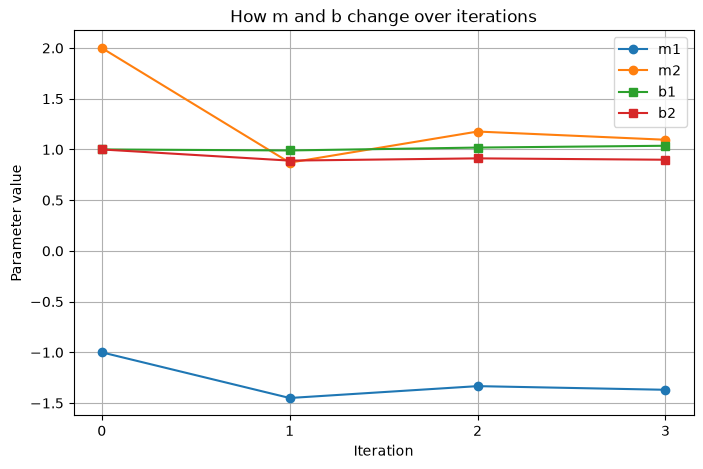

In [7]:
import matplotlib.pyplot as plt

m_history = np.array(history["m"])   # shape (4, 2): iterations 0 to 3
b_history = np.array(history["b"])
iterations = list(range(len(m_history)))

def plot_parameters(iterations, m_history, b_history, save_path=None):
    """Line plot of m1, m2, b1, b2 across iterations."""
    plt.figure(figsize=(8, 5))
    plt.plot(iterations, m_history[:, 0], marker="o", label="m1")
    plt.plot(iterations, m_history[:, 1], marker="o", label="m2")
    plt.plot(iterations, b_history[:, 0], marker="s", label="b1")
    plt.plot(iterations, b_history[:, 1], marker="s", label="b2")
    plt.xlabel("Iteration")
    plt.ylabel("Parameter value")
    plt.title("How m and b change over iterations")
    plt.xticks(iterations)
    plt.legend()
    plt.grid(True)
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_parameters(iterations, m_history, b_history, save_path="gd_parameters.png")

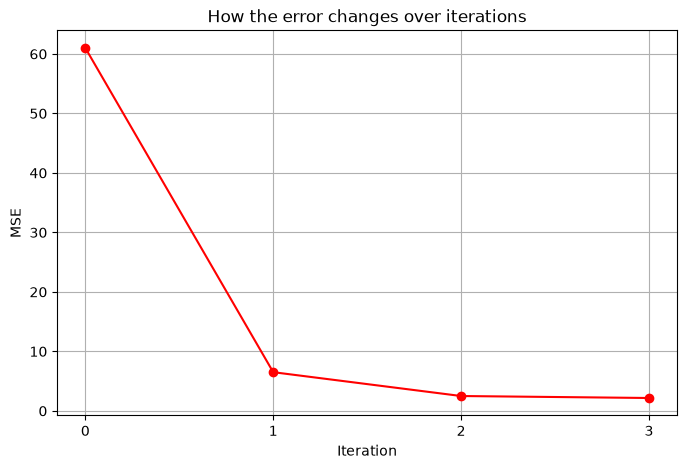

In [8]:
# history["mse"] holds the error BEFORE each update, so add the error after the last update
mse_values = history["mse"] + [compute_mse(predict(X, m, b), y)]

def plot_error(iterations, mse_values, save_path=None):
    """Line plot of the MSE across iterations."""
    plt.figure(figsize=(8, 5))
    plt.plot(iterations, mse_values, marker="o", color="red")
    plt.xlabel("Iteration")
    plt.ylabel("MSE")
    plt.title("How the error changes over iterations")
    plt.xticks(iterations)
    plt.grid(True)
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_error(iterations, mse_values, save_path="gd_error.png")

### Trend and conclusion

- **SciPy check:** the numerical derivatives match our chain-rule formulas for all four parameters (m1, m2, b1, b2), so the gradient formulas are correct.
- **Matches Part 3:** after three updates, m = [-1.369, 1.096] and b = [1.036, 0.899], the same values as our handwritten calculations.
- **Error goes down every update:** 61 → 6.50 → 2.50 → 2.16. So yes, m and b move in a direction that reduces the error.
- **Big first step, then smaller ones:** the starting error is large, so the first gradients are large. As the error shrinks, the gradients and the steps shrink too.
- **Direction changes:** some parameters (for example m1) move one way and then back, because the first step slightly overshoots. The error still falls, which is what matters.
- **Final predictions:** [2.95, 6.38] against the true values [5, 6]. With only three small steps (α = 0.01) the model is not finished; more iterations would keep lowering the error.